<a href="https://colab.research.google.com/github/shreya-1216/Shreya_Colab/blob/main/Text_Preprocessing_%26_Feature_Extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import re
import nltk

import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")

NLTK resources downloaded successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [8]:
data = {
    'text': [
        "Hey, I am Shreya Sharma",
        "I love machine learning and artificial intelligence!",
        "Machine learning is very interesting.",
        "I love programming in Python.",
        "Deep learning is a part of machine learning.",
    ]
}

df = pd.DataFrame(data)

print(df)

                                                text
0                            Hey, I am Shreya Sharma
1  I love machine learning and artificial intelli...
2              Machine learning is very interesting.
3                      I love programming in Python.
4       Deep learning is a part of machine learning.


In [9]:
print("Dataset Shape:", df.shape)
print("\nFirst Five Rows:")
print(df.head())

Dataset Shape: (5, 1)

First Five Rows:
                                                text
0                            Hey, I am Shreya Sharma
1  I love machine learning and artificial intelli...
2              Machine learning is very interesting.
3                      I love programming in Python.
4       Deep learning is a part of machine learning.


In [10]:
df['lowercase_text'] = df['text'].str.lower()

print(df[['text', 'lowercase_text']].head())

                                                text  \
0                            Hey, I am Shreya Sharma   
1  I love machine learning and artificial intelli...   
2              Machine learning is very interesting.   
3                      I love programming in Python.   
4       Deep learning is a part of machine learning.   

                                      lowercase_text  
0                            hey, i am shreya sharma  
1  i love machine learning and artificial intelli...  
2              machine learning is very interesting.  
3                      i love programming in python.  
4       deep learning is a part of machine learning.  


In [11]:
def clean_text(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

df['cleaned_text'] = df['lowercase_text'].apply(clean_text)

print(df[['lowercase_text', 'cleaned_text']].head())

                                      lowercase_text  \
0                            hey, i am shreya sharma   
1  i love machine learning and artificial intelli...   
2              machine learning is very interesting.   
3                      i love programming in python.   
4       deep learning is a part of machine learning.   

                                        cleaned_text  
0                             hey i am shreya sharma  
1  i love machine learning and artificial intelli...  
2               machine learning is very interesting  
3                       i love programming in python  
4        deep learning is a part of machine learning  


In [12]:
df['tokens'] = df['cleaned_text'].apply(lambda text: text.split())

print(df[['cleaned_text', 'tokens']].head())

                                        cleaned_text  \
0                             hey i am shreya sharma   
1  i love machine learning and artificial intelli...   
2               machine learning is very interesting   
3                       i love programming in python   
4        deep learning is a part of machine learning   

                                              tokens  
0                       [hey, i, am, shreya, sharma]  
1  [i, love, machine, learning, and, artificial, ...  
2         [machine, learning, is, very, interesting]  
3                 [i, love, programming, in, python]  
4  [deep, learning, is, a, part, of, machine, lea...  


In [13]:
stop_words = set(stopwords.words('english'))

def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word not in stop_words
    ]

df['filtered_tokens'] = df['tokens'].apply(remove_stopwords)

print(df[['tokens', 'filtered_tokens']].head())

                                              tokens  \
0                       [hey, i, am, shreya, sharma]   
1  [i, love, machine, learning, and, artificial, ...   
2         [machine, learning, is, very, interesting]   
3                 [i, love, programming, in, python]   
4  [deep, learning, is, a, part, of, machine, lea...   

                                     filtered_tokens  
0                              [hey, shreya, sharma]  
1  [love, machine, learning, artificial, intellig...  
2                   [machine, learning, interesting]  
3                        [love, programming, python]  
4          [deep, learning, part, machine, learning]  


In [14]:
stemmer = PorterStemmer()

def apply_stemming(tokens):
    return [
        stemmer.stem(word) for word in tokens
    ]

df['stemmed_tokens'] = df['filtered_tokens'].apply(apply_stemming)

print(df[['filtered_tokens', 'stemmed_tokens']].head())

                                     filtered_tokens  \
0                              [hey, shreya, sharma]   
1  [love, machine, learning, artificial, intellig...   
2                   [machine, learning, interesting]   
3                        [love, programming, python]   
4          [deep, learning, part, machine, learning]   

                              stemmed_tokens  
0                      [hey, shreya, sharma]  
1  [love, machin, learn, artifici, intellig]  
2                  [machin, learn, interest]  
3                    [love, program, python]  
4         [deep, learn, part, machin, learn]  


In [15]:
lemmatizer = WordNetLemmatizer()

def apply_lemmatization(tokens):
    return [
        lemmatizer.lemmatize(word) for word in tokens
    ]

df['lemmatized_tokens'] = df['filtered_tokens'].apply(
    apply_lemmatization
)

print(df[['filtered_tokens', 'lemmatized_tokens']].head())

                                     filtered_tokens  \
0                              [hey, shreya, sharma]   
1  [love, machine, learning, artificial, intellig...   
2                   [machine, learning, interesting]   
3                        [love, programming, python]   
4          [deep, learning, part, machine, learning]   

                                   lemmatized_tokens  
0                              [hey, shreya, sharma]  
1  [love, machine, learning, artificial, intellig...  
2                   [machine, learning, interesting]  
3                        [love, programming, python]  
4          [deep, learning, part, machine, learning]  


In [16]:
df['processed_text'] = df['lemmatized_tokens'].apply(
    lambda tokens: ' '.join(tokens)
)

print(df[['text', 'processed_text']])

                                                text  \
0                            Hey, I am Shreya Sharma   
1  I love machine learning and artificial intelli...   
2              Machine learning is very interesting.   
3                      I love programming in Python.   
4       Deep learning is a part of machine learning.   

                                  processed_text  
0                              hey shreya sharma  
1  love machine learning artificial intelligence  
2                   machine learning interesting  
3                        love programming python  
4            deep learning part machine learning  


In [17]:
corpus = df['processed_text']

bow_vectorizer = CountVectorizer()

bow_matrix = bow_vectorizer.fit_transform(corpus)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=bow_vectorizer.get_feature_names_out()
)

print("Bag of Words Feature Matrix:")
print(bow_df)

Bag of Words Feature Matrix:
   artificial  deep  hey  intelligence  interesting  learning  love  machine  \
0           0     0    1             0            0         0     0        0   
1           1     0    0             1            0         1     1        1   
2           0     0    0             0            1         1     0        1   
3           0     0    0             0            0         0     1        0   
4           0     1    0             0            0         2     0        1   

   part  programming  python  sharma  shreya  
0     0            0       0       1       1  
1     0            0       0       0       0  
2     0            0       0       0       0  
3     0            1       1       0       0  
4     1            0       0       0       0  


In [18]:
print("Vocabulary:")
print(bow_vectorizer.get_feature_names_out())

Vocabulary:
['artificial' 'deep' 'hey' 'intelligence' 'interesting' 'learning' 'love'
 'machine' 'part' 'programming' 'python' 'sharma' 'shreya']


In [19]:
print("BoW Matrix Shape:", bow_matrix.shape)

BoW Matrix Shape: (5, 13)


In [20]:
tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(
    df['processed_text']
)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)

print("TF-IDF Feature Matrix:")
print(tfidf_df.round(3))

TF-IDF Feature Matrix:
   artificial   deep    hey  intelligence  interesting  learning   love  \
0       0.000  0.000  0.577         0.000        0.000     0.000  0.000   
1       0.531  0.000  0.000         0.531        0.000     0.356  0.428   
2       0.000  0.000  0.000         0.000        0.726     0.486  0.000   
3       0.000  0.000  0.000         0.000        0.000     0.000  0.496   
4       0.000  0.485  0.000         0.000        0.000     0.650  0.000   

   machine   part  programming  python  sharma  shreya  
0    0.000  0.000        0.000   0.000   0.577   0.577  
1    0.356  0.000        0.000   0.000   0.000   0.000  
2    0.486  0.000        0.000   0.000   0.000   0.000  
3    0.000  0.000        0.614   0.614   0.000   0.000  
4    0.325  0.485        0.000   0.000   0.000   0.000  


In [21]:
print("TF-IDF Vocabulary:")
print(tfidf_vectorizer.get_feature_names_out())

TF-IDF Vocabulary:
['artificial' 'deep' 'hey' 'intelligence' 'interesting' 'learning' 'love'
 'machine' 'part' 'programming' 'python' 'sharma' 'shreya']


In [22]:
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (5, 13)


In [23]:
ngram_vectorizer = CountVectorizer(
    ngram_range=(1, 2)
)

ngram_matrix = ngram_vectorizer.fit_transform(
    df['processed_text']
)

ngram_df = pd.DataFrame(
    ngram_matrix.toarray(),
    columns=ngram_vectorizer.get_feature_names_out()
)

print("N-gram Feature Matrix:")
print(ngram_df)

N-gram Feature Matrix:
   artificial  artificial intelligence  deep  deep learning  hey  hey shreya  \
0           0                        0     0              0    1           1   
1           1                        1     0              0    0           0   
2           0                        0     0              0    0           0   
3           0                        0     0              0    0           0   
4           0                        0     1              1    0           0   

   intelligence  interesting  learning  learning artificial  ...  machine  \
0             0            0         0                    0  ...        0   
1             1            0         1                    1  ...        1   
2             0            1         1                    0  ...        1   
3             0            0         0                    0  ...        0   
4             0            0         2                    0  ...        1   

   machine learning  part  part m

In [24]:
print(ngram_vectorizer.get_feature_names_out())

['artificial' 'artificial intelligence' 'deep' 'deep learning' 'hey'
 'hey shreya' 'intelligence' 'interesting' 'learning'
 'learning artificial' 'learning interesting' 'learning part' 'love'
 'love machine' 'love programming' 'machine' 'machine learning' 'part'
 'part machine' 'programming' 'programming python' 'python' 'sharma'
 'shreya' 'shreya sharma']


In [25]:
print("Original Dataset Shape:", df.shape)

print("Bag of Words Shape:", bow_matrix.shape)

print("TF-IDF Shape:", tfidf_matrix.shape)

print("N-gram Shape:", ngram_matrix.shape)

Original Dataset Shape: (5, 8)
Bag of Words Shape: (5, 13)
TF-IDF Shape: (5, 13)
N-gram Shape: (5, 25)


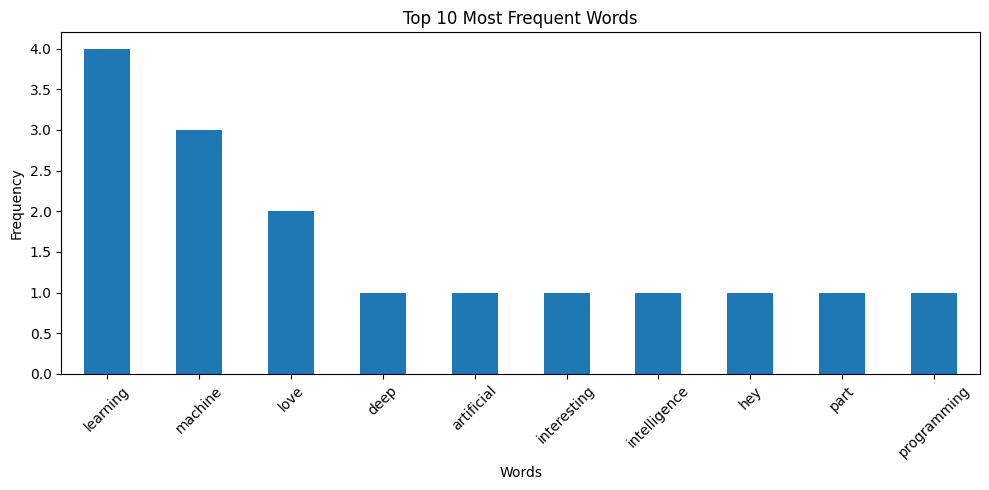

In [26]:
word_counts = bow_df.sum(axis=0).sort_values(
    ascending=False
)

top_words = word_counts.head(10)

plt.figure(figsize=(10, 5))

top_words.plot(kind='bar')

plt.title("Top 10 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
print("Final Preprocessing Results:\n")

print(
    df[
        [
            'text',
            'lowercase_text',
            'cleaned_text',
            'filtered_tokens',
            'stemmed_tokens',
            'processed_text'
        ]
    ].head(10).to_string(index=False)
)

Final Preprocessing Results:

                                                text                                       lowercase_text                                        cleaned_text                                     filtered_tokens                            stemmed_tokens                                processed_text
                             Hey, I am Shreya Sharma                              hey, i am shreya sharma                              hey i am shreya sharma                               [hey, shreya, sharma]                     [hey, shreya, sharma]                             hey shreya sharma
I love machine learning and artificial intelligence! i love machine learning and artificial intelligence! i love machine learning and artificial intelligence [love, machine, learning, artificial, intelligence] [love, machin, learn, artifici, intellig] love machine learning artificial intelligence
               Machine learning is very interesting.                machine 